---

# Pipeline Final Naive Bayes

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Model Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Cost-Sensitive Classification**](#12)
13. [**Bonus Graf Bayesian Network**](#13)

---

# Introduction <a name="1"></a>

---

Tujuan notebook ini adalah memprediksi apakah sebuah reservasi akan dibatalkan. Model akhir memakai K-Dependence Bayesian Classifier atau KDB, yaitu jaringan Bayesian yang mengizinkan ketergantungan terbatas antarf fitur. Seluruh classifier dibuat dari nol, sedangkan scikit-learn hanya dipakai sebagai pembanding.

Alur dimulai dari pemeriksaan data dan pembagian train-validation, lalu menerapkan pembersihan, fitur turunan, binning, dan pengodean kategori. Model dilatih pada data training, dinilai dengan Macro F1, dibandingkan dengan baseline dan estimator scikit-learn, kemudian disimpan bersama preprocessing untuk menghasilkan prediksi test.

## Metrik Evaluasi

Metrik utama adalah *Macro F1*. Nilai F1 dihitung terpisah untuk label 0 dan label 1, lalu dirata-ratakan sehingga kedua kelas memiliki kontribusi yang sama meskipun jumlah contohnya berbeda.

$$\mathrm{MacroF1}=\frac{1}{2}\sum_{c\in\{0,1\}}\mathrm{F1}_c$$

Perhitungan menggunakan `labels=[0, 1]`, `average="macro"`, dan `zero_division=0`. Dengan demikian, kelas yang tidak memiliki prediksi positif tetap memiliki definisi skor yang konsisten.

## Dataset

Data dibaca dari `data/train.csv` dan `data/test.csv`. Kolom `is_canceled` menjadi target biner, sementara `id` hanya dipakai untuk mencocokkan kembali prediksi dengan baris test. Kolom ID tidak dimasukkan ke fitur model agar pengenal baris tidak memengaruhi klasifikasi.

## Rancangan Eksperimen

Indeks validation ditetapkan sebelum eksplorasi yang memakai label. Semua keputusan model memakai pembagian yang sama agar skor dapat dibandingkan secara adil. Nilai imputasi, kategori, dan tepi bin dipelajari hanya dari bagian training atau training fold. Data validation dan test hanya ditransformasikan menggunakan state tersebut.

---

# Initialization <a name="2"></a>

---

Bagian ini menetapkan seed, lokasi data dan artefak, parameter baseline, konfigurasi pipeline final, serta parameter KDB. Nilai konfigurasi dicatat eksplisit agar hasil validasi dapat ditelusuri dan artefak dapat dimuat kembali.

## Lingkungan dan Pustaka

Notebook menggunakan NumPy, pandas, dan scikit-learn. Perintah instalasi dibiarkan tidak aktif karena pustaka tersebut sudah tersedia di lingkungan eksekusi. Versi NumPy dan pandas dicetak untuk membantu reproduksi.

In [4]:
# %pip install -q numpy pandas scikit-learn

Tidak ada dependensi tambahan yang diperlukan untuk implementasi KDB. Estimator dari scikit-learn hanya digunakan dalam eksperimen pembanding.

## Import Pustaka

Import mencakup pengolahan tabel, operasi numerik, metrik evaluasi, serta modul Naive Bayes lokal. Modul lokal digunakan kembali supaya notebook mengikuti implementasi dan format artefak yang sama dengan skrip eksperimen.

In [5]:
import json
import os
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

## Konfigurasi Eksperimen

In [6]:
class Settings:
    SEED = 42
    MODEL_NAME = 'naive_bayes'
    ROOT_DIR = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'data' / 'train.csv').is_file()), Path.cwd())
    DATA_DIR = ROOT_DIR / 'data'
    TRAIN_PATH = DATA_DIR / 'train.csv'
    TEST_PATH = DATA_DIR / 'test.csv'
    OUTPUT_DIR = ROOT_DIR / 'output'
    EXP_OUT_DIR = OUTPUT_DIR / 'experiments' / MODEL_NAME
    MODEL_DIR = OUTPUT_DIR / 'final' / 'model' / MODEL_NAME

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.EXP_OUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(CFG.SEED)
np.random.seed(CFG.SEED)
os.environ['PYTHONHASHSEED'] = str(CFG.SEED)

if str(CFG.ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(CFG.ROOT_DIR))

from src.experiments.naive_bayes.utils.cleaning import clean_training_data, mask_invalid_values
from src.experiments.naive_bayes.utils.kdb import KDBClassifier
from src.experiments.naive_bayes.utils.naive_bayes import NaiveBayesClassifier
from src.experiments.naive_bayes.utils.pipeline import StagePipeline, feature_frame, model_from_params
from src.experiments.naive_bayes.utils.preprocessing import (
    DEFAULT_BIN_COLS,
    DEFAULT_CATEGORICAL_NUMERIC,
    DEFAULT_LOG1P_COLS,
    NaiveBayesPreprocessor,
)
from src.experiments.naive_bayes.run_naive_bayes import _categorical_comparison, _gaussian_comparison

BASELINE_PREP = {
    'name': 'mandatory_baseline_bin_q20',
    'feature_set': 'baseline',
    'options': {
        'standardize': False,
        'add_missing_indicators': True,
        'categorical_numeric_cols': list(DEFAULT_CATEGORICAL_NUMERIC),
        'log1p_cols': list(DEFAULT_LOG1P_COLS),
        'bin_cols': list(DEFAULT_BIN_COLS),
        'n_bins': 20,
        'bin_strategy': 'quantile',
    },
}
BASELINE_PARAMS = {
    'mode': 'baseline',
    'variant': 'categorical',
    'alpha': 1.0,
    'var_smoothing': 0.0,
    'threshold': 0.5,
    'feature_weights': None,
}
BASELINE_CV_F1 = 0.74656

FINAL_PREP = {'name': 'bin_all_q30',
 'feature_set': ['ota_x_requests',
                 'rate_weekend_req_ota',
                 'lead_x_weekend_req',
                 'channel_x_meal',
                 'is_offline'],
 'options': {'standardize': False,
             'add_missing_indicators': True,
             'categorical_numeric_cols': ['needs_parking',
                                          'is_returning_guest',
                                          'arrival_year',
                                          'arrival_month',
                                          'special_requests',
                                          'num_adults',
                                          'num_children',
                                          'weekend_nights',
                                          'weekday_nights',
                                          'prior_cancellations',
                                          'is_offline'],
             'log1p_cols': ['days_before_arrival',
                            'nightly_rate_idr',
                            'prior_completed_bookings'],
             'bin_cols': ['days_before_arrival',
                          'nightly_rate_idr',
                          'prior_completed_bookings',
                          'arrival_day'],
             'n_bins': 25,
             'bin_strategy': 'quantile'}}
SELECTED_FEATURES = None
FINAL_DR = {'method': 'none'}
PARAMS = {'variant': 'kdb',
 'k': 4,
 'm_estimate': 100.0,
 'alpha': 1.0,
 'var_smoothing': 0.05,
 'threshold': 0.405,
 'bias': 0.0,
 'feature_weights': [0.75,
                     0.75,
                     0.5,
                     1.0,
                     0.25,
                     0.5,
                     1.0,
                     1.0,
                     1.25,
                     1.0,
                     1.0,
                     0.5,
                     0.75,
                     0.0,
                     1.0,
                     1.0,
                     1.5,
                     0.75,
                     1.5,
                     0.75,
                     0.5,
                     2.0]}
CV_MACRO_F1 = 0.817709
print('numpy', np.__version__, '| pandas', pd.__version__)

numpy 1.26.4 | pandas 2.2.2


## Memuat Dataset dan Menetapkan Split

In [7]:
train_df = pd.read_csv(CFG.TRAIN_PATH, dtype={'id': str})
test_df = pd.read_csv(CFG.TEST_PATH, dtype={'id': str})
print(f'Train: {train_df.shape} | Test: {test_df.shape}')

# Create the holdout before any target-aware exploration.
y_all = train_df['is_canceled'].to_numpy()
if not np.isin(y_all, [0, 1]).all():
    raise ValueError('Target is expected to contain only labels 0 and 1.')
rng = np.random.default_rng(CFG.SEED)
valid_idx = np.sort(np.concatenate([
    rng.permutation(np.flatnonzero(y_all == label))[:int(np.ceil(0.2 * np.sum(y_all == label)))]
    for label in (0, 1)
]))
train_idx = np.setdiff1d(np.arange(len(train_df)), valid_idx)
train_set = train_df.iloc[train_idx].copy()
val_set = train_df.iloc[valid_idx].copy()

Train: (27373, 19) | Test: (6844, 18)


Seed 42 digunakan untuk memilih sekitar 20% contoh dari setiap kelas sebagai validation. Indeks train dan validation tidak diubah setelah eksplorasi. Cara ini mempertahankan proporsi kelas sekaligus memastikan seluruh konfigurasi dinilai pada baris yang sama.

---

# Data Understanding <a name="3"></a>

---

Pemeriksaan berikut merangkum bentuk tabel, tipe kolom, nilai kosong, duplikasi, dan rentang numerik. Analisis yang memakai target dibatasi pada `train_set`. Label validation tidak dipakai untuk merancang fitur atau membersihkan data.

## Ringkasan Data

In [8]:
feature_columns = [column for column in train_df.columns if column not in {'id', 'is_canceled'}]
train_features = train_set[feature_columns]
feature_profile = pd.DataFrame({
    'dtype': train_features.dtypes.astype(str),
    'missing': train_features.isna().sum(),
    'missing_pct': train_features.isna().mean().mul(100).round(2),
    'unique': train_features.nunique(dropna=True),
})
display(feature_profile)

target_counts = train_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({'count': target_counts, 'proportion': target_counts / len(train_set)}, index=[0, 1]))

,dtype,missing,missing_pct,unique
num_adults,float64,652,2.98,5
num_children,float64,2453,11.20,6
weekend_nights,int64,0,0.00,8
weekday_nights,int64,0,0.00,18
meal_package,object,1413,6.45,4
needs_parking,float64,865,3.95,2
room_category,object,811,3.70,7
days_before_arrival,float64,909,4.15,403
arrival_year,int64,0,0.00,2
arrival_month,int64,0,0.00,12


,count,proportion
0,14723,0.672345
1,7175,0.327655


Ringkasan statistik membantu mengenali skala fitur dan kemungkinan nilai ekstrem. Ringkasan ini bersifat deskriptif dan tidak mengubah nilai masukan.

## Eksplorasi Fitur dan Target

In [9]:
numeric_features = train_features.select_dtypes(include='number').columns
categorical_features = train_features.select_dtypes(exclude='number').columns

display(train_set.groupby('is_canceled')[numeric_features].median().T.rename(columns={0: 'not_canceled', 1: 'canceled'}))
for column in categorical_features:
    category_summary = train_set.assign(category=train_set[column].fillna('__MISSING__')).groupby('category', dropna=False)['is_canceled'].agg(count='size', cancellation_rate='mean')
    display(category_summary.sort_values('count', ascending=False))

is_canceled,not_canceled,canceled
num_adults,2.0,2.0
num_children,0.0,0.0
weekend_nights,1.0,1.0
weekday_nights,2.0,2.0
needs_parking,0.0,0.0
days_before_arrival,39.0,122.0
arrival_year,2024.0,2024.0
arrival_month,8.0,8.0
arrival_day,15.0,16.0
is_returning_guest,0.0,0.0


,count,cancellation_rate
category,,
Breakfast,15716,0.310957
Room Only,2981,0.338812
Half Board,1784,0.459081
__MISSING__,1413,0.324133
Full Board,4,0.250000


,count,cancellation_rate
category,,
Type B,16325,0.320674
Type G,3507,0.341888
__MISSING__,811,0.361282
Type A,572,0.430070
Type D,429,0.328671
Type C,152,0.236842
Type F,96,0.239583
Type E,6,0.333333


,count,cancellation_rate
category,,
Online Travel Agent,14036,0.363138
Offline Agent,6357,0.301715
Corporate,1189,0.116905
Complimentary,241,0.000000
Airline,75,0.280000


Pola pada data training dapat mengusulkan fitur turunan, tetapi dugaan tersebut tetap perlu diuji dengan cross-validation. Hasil eksplorasi bukan bukti sebab-akibat dan tidak digunakan untuk melihat label validation.

## Kualitas Data

In [10]:
test_features = test_df.drop(columns='id')
quality_checks = {
    'unique IDs in train': train_df['id'].is_unique,
    'unique IDs in test': test_df['id'].is_unique,
    'train and test feature columns match': set(feature_columns) == set(test_features.columns),
    'binary training target': set(train_set['is_canceled'].unique()).issubset({0, 1}),
}
display(pd.Series(quality_checks, name='passed').to_frame())
if not all(quality_checks.values()):
    raise ValueError('Review data quality checks before continuing.')

,passed
unique IDs in train,True
unique IDs in test,True
train and test feature columns match,True
binary training target,True


Nilai yang berada di luar domain ditandai sebagai missing oleh fungsi pembersihan. Baris training yang identik pada fitur dan label dibuang, sedangkan nilai fitur identik dengan label berbeda tidak dianggap duplikat yang aman untuk dihapus.

---

# Training and Validation Split <a name="4"></a>

---

Split dibuat pada awal notebook sebelum eksplorasi. `train_idx` dipakai untuk melatih dan memilih konfigurasi, sedangkan `valid_idx` menjadi holdout tetap untuk pelaporan akhir.

In [11]:
split_class_counts = pd.DataFrame({
    'train': train_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0),
    'validation': val_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0),
})
display(split_class_counts)

cross_split_duplicates = train_set[feature_columns].drop_duplicates().merge(
    val_set[feature_columns].drop_duplicates(), on=feature_columns, how='inner'
).shape[0]
print(f'Identical feature rows across train and validation: {cross_split_duplicates}')

,train,validation
is_canceled,,
0,14723,3681
1,7175,1794


Identical feature rows across train and validation: 25


Periksa jumlah contoh per kelas dan potensi duplikasi lintas split. Split tidak boleh diubah setelah skor validation diketahui karena perubahan tersebut akan mengurangi keterbandingan hasil.

---

# Data Preparation <a name="5"></a>

---

Persiapan data dirancang khusus untuk Naive Bayes. Konfigurasi final menambahkan lima fitur turunan, mengubah fitur numerik terpilih menjadi kategori, mempertahankan indikator missing, dan tidak memakai scaling maupun reduksi dimensi.

## Memilih Kolom Fitur

In [12]:
X_train_raw = train_set[feature_columns].copy()
X_val_raw = val_set[feature_columns].copy()
X_test_raw = test_df[feature_columns].copy()
y_train = train_set['is_canceled'].to_numpy(dtype=int)
y_val = val_set['is_canceled'].to_numpy(dtype=int)

if X_train_raw.columns.tolist() != X_val_raw.columns.tolist() or X_train_raw.columns.tolist() != X_test_raw.columns.tolist():
    raise ValueError('Train, validation, and test feature columns must match in the same order.')
if {'id', 'is_canceled'} & set(feature_columns):
    raise ValueError('ID and target must not be used as model features.')
print(f'Features: {len(feature_columns)} | train: {len(X_train_raw)} | validation: {len(X_val_raw)} | test: {len(X_test_raw)}')

Features: 17 | train: 21898 | validation: 5475 | test: 6844


`id` disimpan terpisah untuk membuat submission. Seluruh transformasi mempertahankan urutan baris sehingga prediksi tetap berpasangan dengan ID asal.

## Pembersihan Data

### Nilai Hilang

In [13]:
missing_summary = pd.DataFrame({
    'train': X_train_raw.isna().sum(),
    'validation': X_val_raw.isna().sum(),
    'test': X_test_raw.isna().sum(),
})
display(missing_summary.loc[missing_summary.any(axis=1)].sort_values('train', ascending=False))

,train,validation,test
num_children,2453,582,747
special_requests,2029,471,593
nightly_rate_idr,1640,398,540
meal_package,1413,347,442
days_before_arrival,909,214,290
needs_parking,865,217,247
room_category,811,191,242
num_adults,652,157,180


Fitur kategorikal memiliki kategori khusus untuk nilai missing dan kategori yang belum pernah terlihat. Fitur numerik yang tidak dibinning diimputasi dengan median training. Indikator missing ditambahkan bila kolom numerik memiliki nilai kosong pada data fit.

### Baris Duplikat

In [14]:
duplicate_mask = X_train_raw.duplicated(subset=feature_columns, keep=False)
print(f'Training rows with duplicate features: {int(duplicate_mask.sum())}')

Training rows with duplicate features: 79


Pembersihan training menghapus baris dengan fitur dan label yang sama, dengan mempertahankan kemunculan pertama. Pembersihan tidak diterapkan dengan cara yang mengubah jumlah atau urutan baris validation dan test.

### Nilai di Luar Rentang

In [15]:
numeric_columns = X_train_raw.select_dtypes(include='number').columns
quartiles = X_train_raw[numeric_columns].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
lower, upper = quartiles.loc[0.25] - 1.5 * iqr, quartiles.loc[0.75] + 1.5 * iqr
outlier_counts = ((X_train_raw[numeric_columns] < lower) | (X_train_raw[numeric_columns] > upper)).sum()
display(outlier_counts.rename('iqr_outliers').to_frame().sort_values('iqr_outliers', ascending=False))

,iqr_outliers
num_adults,5850
arrival_year,3925
num_children,1626
nightly_rate_idr,924
days_before_arrival,739
needs_parking,637
is_returning_guest,546
prior_completed_bookings,476
special_requests,436
weekday_nights,200


Nilai negatif pada kolom yang seharusnya nonnegatif serta nilai bulan, hari, dan indikator di luar rentang valid ditandai sebagai missing. Batas tersebut berasal dari domain kolom, bukan statistik yang dihitung dari validation.

### Data Errors

Catat nilai di luar domain, tipe yang tidak sesuai, atau ketidakkonsistenan yang relevan untuk model ini sebelum mengubah data.

## Fitur Turunan dan Representasi

### Fitur Turunan

Lima fitur yang dipakai adalah `ota_x_requests`, `rate_weekend_req_ota`, `lead_x_weekend_req`, `channel_x_meal`, dan `is_offline`. Fitur gabungan merangkum kanal pemesanan, permintaan khusus, tarif, waktu pemesanan, malam akhir pekan, dan paket makanan. Transformasi hanya memakai nilai dalam baris yang sama dan tidak membaca target.

### Scaling

Scaling tidak digunakan pada konfigurasi final karena seluruh fitur yang masuk ke KDB berbentuk kategori. Scaling baru relevan jika pipeline menggunakan fitur numerik kontinu.

### Pengodean Kategori dan Binning

Fitur kategorikal diubah menjadi kode integer. Empat fitur numerik pada `bin_cols` dibagi menjadi 25 bin kuantil. Batas bin dipelajari dari data fit. Kategori missing dan kategori tak dikenal memiliki kode khusus agar transformasi validation dan test tetap terdefinisi.

### Seleksi Fitur dan Reduksi Dimensi

Semua fitur tersedia digunakan, sehingga `SELECTED_FEATURES` bernilai `None`. Reduksi dimensi tidak diterapkan karena `FINAL_DR` memakai `{"method": "none"}`. Dengan demikian setiap fitur kategorikal tetap tersedia bagi KDB.

## Distribusi Kelas

Proporsi kelas diperiksa pada bagian train dan validation. Konfigurasi final tidak memakai resampling atau bobot kelas eksplisit. Macro F1 memberi kontribusi yang sama pada skor kedua kelas.

## Bentuk Masukan Model

Preprocessor menghasilkan matriks dua dimensi dengan satu kolom kode kategori untuk setiap fitur. Urutan fitur dan jumlah kategori disimpan dalam objek pipeline sehingga KDB membaca kode yang konsisten saat fit dan prediksi.

---

# Model Pipeline <a name="6"></a>

---

Pipeline menjalankan pemeriksaan domain, pembuatan fitur turunan, pemilihan kolom, imputasi atau binning, dan pengodean. Semua state yang dipelajari berasal dari data training. Objek `StagePipeline` menyatukan transformasi tersebut sehingga validation dan test menerima langkah yang sama.

In [16]:
def fit_preprocessor(X_fit, y_fit=None):
    """Fit preprocessing (discretization + encoding) on training data only."""
    if y_fit is not None:
        X_fit, y_fit, _ = clean_training_data(X_fit, y_fit)
    return StagePipeline(FINAL_PREP, SELECTED_FEATURES, FINAL_DR).fit(X_fit, y_fit)


def transform_features(preprocessor, X):
    """Transform without fitting on X; preserves row count and order."""
    if preprocessor is None:
        return X.copy()
    if isinstance(preprocessor, StagePipeline):
        return preprocessor.transform(X)
    X_frame = feature_frame(mask_invalid_values(X), FINAL_PREP.get('feature_set', 'baseline'))
    if SELECTED_FEATURES is not None:
        X_frame = X_frame[SELECTED_FEATURES]
    return preprocessor.transform(X_frame)

X_train_clean, y_train_clean, n_dropped_train = clean_training_data(X_train_raw, y_train)
print(f'Duplikat latih dibuang (hanya train_idx): {n_dropped_train}')
preprocessor = fit_preprocessor(X_train_raw, y_train)
X_train_model = transform_features(preprocessor, X_train_raw)
X_val_model = transform_features(preprocessor, X_val_raw)

if len(X_train_model) != len(y_train) or len(X_val_model) != len(y_val):
    raise ValueError('Preprocessing must preserve row count and order.')
print(preprocessor.pre_)

Duplikat latih dibuang (hanya train_idx): 40
NaiveBayesPreprocessor(n_fitur=22, numerik=0, kategorik=22, indikator_missing=0, binned=4)


Setiap fold cross-validation membuat dan mem-fit pipeline sendiri hanya pada bagian training fold. Praktik ini mencegah informasi dari fold evaluasi masuk ke imputasi atau batas bin.

---

# Modeling and Validation <a name="7"></a>

---

Bagian ini membandingkan baseline kategorikal wajib dengan KDB. Baseline memakai Naive Bayes kategorikal, Laplace smoothing `alpha=1.0`, dan threshold `0.5`. KDB menjadi model final dan mengizinkan ketergantungan terbatas antarf fitur.

In [17]:
selected_config = dict(PARAMS)


def train_model(X_raw_fit, y_fit, config, fitted_pipe=None):
    """Train Naive Bayes / KDB from scratch on cleaned training rows."""
    X_c, y_c, _ = clean_training_data(X_raw_fit, y_fit)
    pipe = fitted_pipe or fit_preprocessor(X_c, y_c)
    Z = pipe.transform(X_c)
    return model_from_params(pipe, config).fit(Z, y_c)


def predict_model(model, X):
    """Return one integer label 0 or 1 per input row."""
    return model.predict(X)


# --- 7A. Mandatory Baseline (Sesuai Slide IF3170) ---
# Kategorikal murni hasil diskritisasi (n_bins=20), Laplace smoothing +1 (alpha=1.0),
# MAP murni (threshold=0.5), tanpa Gaussian dan tanpa feature_weights.
pipe_base = StagePipeline(BASELINE_PREP, None, {'method': 'none'}).fit(X_train_clean, y_train_clean)
assert len(pipe_base.numeric_indices) == 0, 'Mandatory baseline wajib kategorikal murni'
model_base = model_from_params(pipe_base, BASELINE_PARAMS).fit(
    pipe_base.transform(X_train_clean), y_train_clean
)
y_val_base = model_base.predict(pipe_base.transform(X_val_raw))
macro_base = f1_score(y_val, y_val_base, labels=[0, 1], average='macro', zero_division=0)
cm_base = confusion_matrix(y_val, y_val_base, labels=[0, 1])
p_b, r_b, f_b, s_b = precision_recall_fscore_support(y_val, y_val_base, labels=[0, 1], zero_division=0)
print(f'[Mandatory Baseline] Holdout Macro F1: {macro_base:.6f} (CV 3-seed: {BASELINE_CV_F1:.6f})')
print(f'Prior P(v_j): class 0 = {model_base.class_prior_[0]:.4f}, class 1 = {model_base.class_prior_[1]:.4f}')
print(f"Contoh tabel P(a_i | v_j) fitur '{pipe_base.pre_.feature_names_[0]}':\n{np.round(model_base.cat_probs_[0][:, :4], 4)}")
display(pd.DataFrame({'precision': p_b, 'recall': r_b, 'f1': f_b, 'support': s_b}, index=[0, 1]))
display(pd.DataFrame(cm_base, index=[0, 1], columns=[0, 1]))

[Mandatory Baseline] Holdout Macro F1: 0.753704 (CV 3-seed: 0.746560)
Prior P(v_j): class 0 = 0.6725, class 1 = 0.3275
Contoh tabel P(a_i | v_j) fitur 'num_adults':
[[0.0039 0.2274 0.6826 0.0559]
 [0.0042 0.1493 0.7446 0.0703]]


,precision,recall,f1,support
0,0.824328,0.874491,0.848669,3681
1,0.705732,0.617614,0.658740,1794


,0,1
0,3219,462
1,686,1108


Skor final yang tercatat adalah Macro F1 validation `0.821914` dan rata-rata cross-validation tiga seed `0.817709`. Baseline mencatat Macro F1 validation `0.753704` dan rata-rata cross-validation `0.746560`. Skor validation berfungsi sebagai holdout, sedangkan pemilihan threshold dilakukan dengan skor out-of-fold pada data training.

In [18]:
# --- 7B. Bonus: Optimasi Performa dengan KDB, fitur turunan, bobot, dan threshold ---
# Referensi: Sahami (1996), Friedman dkk. (1997), Cestnik (1990), Zaidi dkk. (2013).
model = train_model(X_train_raw, y_train, selected_config, fitted_pipe=preprocessor)
val_scores = model.decision_scores(X_val_model)
y_val_pred = np.asarray(predict_model(model, X_val_model))
if y_val_pred.ndim != 1 or len(y_val_pred) != len(y_val):
    raise ValueError('Validation prediction must contain one label per validation row.')
if not np.isin(y_val_pred, [0, 1]).all():
    raise ValueError('Predictions must be labels 0 or 1.')
y_val_pred = y_val_pred.astype(int)

validation_macro_f1 = f1_score(y_val, y_val_pred, labels=[0, 1], average='macro', zero_division=0)
validation_confusion = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
precision, recall, class_f1, support = precision_recall_fscore_support(y_val, y_val_pred, labels=[0, 1], zero_division=0)
print(f'[Bonus KDB] Validation Macro F1: {validation_macro_f1:.6f} (CV 3-seed: {CV_MACRO_F1:.6f})')
print(f'Kenaikan vs Mandatory Baseline: {validation_macro_f1 - macro_base:+.6f} (holdout), {CV_MACRO_F1 - BASELINE_CV_F1:+.6f} (CV)')
display(pd.DataFrame({'precision': precision, 'recall': recall, 'f1': class_f1, 'support': support}, index=[0, 1]))
display(pd.DataFrame(validation_confusion, index=[0, 1], columns=[0, 1]))

[Bonus KDB] Validation Macro F1: 0.821914 (CV 3-seed: 0.817709)
Kenaikan vs Mandatory Baseline: +0.068210 (holdout), +0.071149 (CV)


,precision,recall,f1,support
0,0.873191,0.901657,0.887196,3681
1,0.783751,0.731327,0.756632,1794


,0,1
0,3319,362
1,482,1312


KDB memakai `k=4`, `m_estimate=100.0`, `alpha=1.0`, threshold `0.405`, bias `0.0`, serta bobot fitur yang tersimpan di `PARAMS`. Nilai `k` membatasi jumlah induk fitur. `m_estimate` mengatur penyusutan estimasi kondisional menuju estimasi dengan tingkat induk lebih rendah. Threshold menentukan batas prediksi kelas 1. `var_smoothing=0.05` tetap tercatat di konfigurasi, tetapi tidak digunakan oleh KDB karena model ini tidak memiliki fitur numerik.

---

# Comparison with scikit-learn <a name="8"></a>

---

Dua pembanding dijalankan pada split validation yang sama. `GaussianNB` menerima fitur numerik dan representasi one-hot untuk fitur kategori, sedangkan `CategoricalNB` menerima kode kategori dan binning. Keduanya hanya menjadi pembanding, bukan pengganti implementasi KDB dari nol.

In [19]:
comparison_config = {'variant': 'gaussian', 'variance_smoothing': 1e-9, 'alpha': PARAMS['alpha']}
X_all_raw = train_df[feature_columns].copy()
comparison = {}
for name, predictor in (
    ('GaussianNB_numeric+onehot', _gaussian_comparison),
    ('CategoricalNB_binned', _categorical_comparison),
):
    pred_sk = predictor(
        X_all_raw, y_all, train_idx, valid_idx, PARAMS,
        prep_cfg=FINAL_PREP,
        selected_features=SELECTED_FEATURES,
        dr_cfg=FINAL_DR,
    )
    if pred_sk.shape != y_val.shape or not np.isin(pred_sk, [0, 1]).all():
        raise ValueError('Comparator must return one binary label per validation row.')
    comparison[name] = f1_score(y_val, pred_sk, labels=[0, 1], average='macro', zero_division=0)
    print(f'scikit-learn {name} Macro F1: {comparison[name]:.6f}')
comparison_macro_f1 = comparison['CategoricalNB_binned']

scikit-learn GaussianNB_numeric+onehot Macro F1: 0.701035
scikit-learn CategoricalNB_binned Macro F1: 0.794346


Macro F1 pembanding dilaporkan berdampingan dengan model utama. Perbedaan preprocessing antar-estimator dicatat karena asumsi input GaussianNB dan CategoricalNB tidak sama dengan asumsi KDB.

---

# Saving and Loading Models <a name="9"></a>

---

Setelah evaluasi, preprocessing dan model di-fit ulang pada seluruh data training yang telah dibersihkan. Bundel berisi state model NumPy, konfigurasi preprocessing, dan parameter model. Notebook memuat ulang bundel tersebut lalu memastikan prediksinya identik dengan prediksi sebelum pemuatan.

In [20]:
X_full_raw = train_df[feature_columns].copy()
y_full = train_df['is_canceled'].to_numpy(dtype=int)
X_full_clean, y_full_clean, n_dropped_full = clean_training_data(X_full_raw, y_full)
print(f'Duplikat seluruh train dibuang: {n_dropped_full}')
final_preprocessor = fit_preprocessor(X_full_raw, y_full)
final_model = train_model(X_full_raw, y_full, selected_config, fitted_pipe=final_preprocessor)

CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)


def save_model_bundle(path, preprocessor_pipe, model_obj):
    np.savez_compressed(path / 'naive_bayes_model.npz', **model_obj.export_state())
    (path / 'preprocessing.json').write_text(
        json.dumps(preprocessor_pipe.pre_.to_dict(), ensure_ascii=False, indent=2)
    )
    config_payload = {
        'algorithm': 'KDB (Bayesian Network) from scratch',
        'variant': selected_config.get('variant', 'kdb'),
        'params': selected_config,
        'preprocessing': FINAL_PREP,
        'cleaning': {'dropped_train_duplicates': n_dropped_full},
        'mandatory_baseline': {
            'mode': 'baseline',
            'variant': 'categorical',
            'alpha': 1.0,
            'threshold': 0.5,
            'n_bins': 20,
            'macro_f1_cv': BASELINE_CV_F1,
            'macro_f1_holdout': round(float(macro_base), 6),
        },
        'feature_selection': {'method': 'none', 'selected_features': SELECTED_FEATURES},
        'dimensionality_reduction': FINAL_DR,
        'seed': CFG.SEED,
        'macro_f1_validasi': round(float(validation_macro_f1), 6),
        'macro_f1_cv': CV_MACRO_F1,
        'macro_f1_holdout': round(float(validation_macro_f1), 6),
        'model_params': model_obj.get_params(),
        'dr_state': {'method': 'none'},
        'sklearn_comparison': {k: round(float(v), 6) for k, v in comparison.items()},
        'library_versions': {'numpy': np.__version__, 'pandas': pd.__version__},
    }
    (path / 'konfigurasi.json').write_text(json.dumps(config_payload, ensure_ascii=False, indent=2))


def load_model_bundle(path):
    loaded = np.load(path / 'naive_bayes_model.npz')
    state_loaded = {k: loaded[k] for k in loaded.files}
    pre_loaded = NaiveBayesPreprocessor.from_dict(
        json.loads((path / 'preprocessing.json').read_text())
    )
    cfg_loaded = json.loads((path / 'konfigurasi.json').read_text())
    cls = KDBClassifier if cfg_loaded.get('variant') == 'kdb' else NaiveBayesClassifier
    model_loaded = cls.from_state(cfg_loaded['model_params'], state_loaded)
    return pre_loaded, model_loaded


save_model_bundle(CFG.MODEL_DIR, final_preprocessor, final_model)
loaded_preprocessor, loaded_model = load_model_bundle(CFG.MODEL_DIR)
pred_direct = predict_model(final_model, transform_features(final_preprocessor, X_test_raw))
pred_reloaded = predict_model(loaded_model, transform_features(loaded_preprocessor, X_test_raw))
np.testing.assert_array_equal(pred_direct, pred_reloaded)
print('Model tersimpan dan hasil muat-ulang identik dengan prediksi langsung:', CFG.MODEL_DIR)

Duplikat seluruh train dibuang: 64
Model tersimpan dan hasil muat-ulang identik dengan prediksi langsung: c:\Users\aufar\Institut Teknologi Bandung\IF3170_G03_FiveAgents\output\final\model\naive_bayes


Berkas harus berasal dari sumber tepercaya. Uji muat ulang memeriksa konsistensi state dan transformasi, tetapi tidak menggantikan pencatatan versi lingkungan atau pengamanan akses artefak.

---

# Kaggle Submission <a name="10"></a>

---

Prediksi test dihitung menggunakan preprocessor dan model yang baru dimuat. Kolom `id` dipertahankan sesuai urutan dalam `test.csv`, sementara `is_canceled` berisi label integer 0 atau 1.

In [21]:
X_test_final = transform_features(loaded_preprocessor, X_test_raw)
test_predictions = np.asarray(predict_model(loaded_model, X_test_final))
if test_predictions.ndim != 1 or len(test_predictions) != len(test_df) or not np.isin(test_predictions, [0, 1]).all():
    raise ValueError('Test prediction must contain one label 0 or 1 per test row.')
test_predictions = test_predictions.astype(int)

submission = pd.DataFrame({'id': test_df['id'].to_numpy(), 'is_canceled': test_predictions})
if submission.columns.tolist() != ['id', 'is_canceled'] or not submission['id'].equals(test_df['id'].reset_index(drop=True)):
    raise ValueError('Submission columns, IDs, and row order must match test.csv exactly.')
submission_path = CFG.EXP_OUT_DIR / f'submission_{CFG.MODEL_NAME}.csv'
submission.to_csv(submission_path, index=False)
print(f'Saved {len(submission)} rows to {submission_path} | distribusi: {submission["is_canceled"].value_counts().to_dict()}')

Saved 6844 rows to c:\Users\aufar\Institut Teknologi Bandung\IF3170_G03_FiveAgents\output\experiments\naive_bayes\submission_naive_bayes.csv | distribusi: {0: 4709, 1: 2135}


Berkas submission memiliki kolom `id` dan `is_canceled`, satu baris untuk setiap baris test, serta urutan ID yang sama persis dengan data masukan.

---

# Error Analysis <a name="11"></a>

---

Pemeriksaan kualitas memisahkan nilai yang tidak valid dari nilai ekstrem yang masih mungkin terjadi. Fungsi `mask_invalid_values` hanya menerapkan aturan domain yang telah ditetapkan.

In [22]:
error_analysis = X_val_raw.copy()
error_analysis['actual'] = y_val
error_analysis['predicted'] = y_val_pred
error_analysis['error_type'] = np.select(
    [error_analysis['actual'].eq(0) & error_analysis['predicted'].eq(1),
     error_analysis['actual'].eq(1) & error_analysis['predicted'].eq(0)],
    ['false_positive', 'false_negative'],
    default='correct',
)
display(error_analysis.loc[error_analysis['error_type'] != 'correct'].head(20))
display(error_analysis['error_type'].value_counts())

# Analisis Cost-Sensitive Classification (Bonus: biaya FP = 2 x FN -> threshold optimal 2/3)
cost_thr = 2.0 / 3.0
print('\n[Bonus Cost-Sensitive Classification: 2*FP + FN]')
for label, thr in (('F1-optimal', PARAMS['threshold']), ('Cost-optimal (2*FP+FN)', cost_thr)):
    p_thr = (val_scores > thr).astype(np.int64)
    cm_t = confusion_matrix(y_val, p_thr, labels=[0, 1])
    cost = 2 * int(cm_t[0, 1]) + int(cm_t[1, 0])
    f1_t = f1_score(y_val, p_thr, labels=[0, 1], average='macro', zero_division=0)
    print(f'  {label} (thr={thr:.4f}): FP={cm_t[0,1]}, FN={cm_t[1,0]}, total_cost={cost}, macro_f1={f1_t:.6f}')

,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,actual,predicted,error_type
35,2.0,0.0,2,4,Breakfast,0.0,Type B,156.0,2024,4,26,Offline Agent,0,0,0,1456000.0,0.0,1,0,false_negative
55,1.0,0.0,1,1,NaN,0.0,Type B,306.0,2024,7,29,Offline Agent,0,0,0,1528000.0,0.0,0,1,false_positive
69,2.0,0.0,2,4,Breakfast,0.0,Type G,26.0,2024,3,11,Online Travel Agent,0,0,0,1697000.0,0.0,0,1,false_positive
71,2.0,0.0,0,2,Breakfast,0.0,Type B,NaN,2024,5,25,Online Travel Agent,0,0,0,1968000.0,0.0,1,0,false_negative
83,2.0,0.0,2,3,Breakfast,0.0,Type B,191.0,2024,11,30,Offline Agent,0,0,0,NaN,NaN,0,1,false_positive
91,2.0,0.0,0,3,Breakfast,0.0,NaN,24.0,2024,10,3,Online Travel Agent,0,0,0,NaN,0.0,0,1,false_positive
136,2.0,0.0,0,1,Breakfast,0.0,Type G,88.0,2024,9,15,Online Travel Agent,0,0,0,2395000.0,1.0,1,0,false_negative
139,2.0,0.0,0,3,Breakfast,0.0,Type G,125.0,2024,9,28,Online Travel Agent,0,0,0,2301000.0,2.0,1,0,false_negative
149,2.0,0.0,1,2,Breakfast,0.0,Type B,98.0,2024,4,3,Offline Agent,0,0,0,NaN,0.0,1,0,false_negative
161,2.0,0.0,0,3,Breakfast,0.0,Type G,80.0,2024,9,7,Online Travel Agent,0,0,0,2404000.0,1.0,1,0,false_negative


error_type
correct           4631
false_negative     482
false_positive     362
Name: count, dtype: int64


[Bonus Cost-Sensitive Classification: 2*FP + FN]
  F1-optimal (thr=0.4050): FP=362, FN=482, total_cost=1206, macro_f1=0.821914
  Cost-optimal (2*FP+FN) (thr=0.6667): FP=202, FN=653, total_cost=1057, macro_f1=0.809007


Pola false positive dan false negative dapat menjadi dasar hipotesis eksperimen berikutnya. Contoh threshold berbasis biaya menggunakan asumsi biaya false positive dua kali biaya false negative. Asumsi ini hanya ilustrasi dan tidak mengubah konfigurasi final.

---

# Cost-Sensitive Classification <a name="12"></a>

---

Jika FP berbiaya dua kali FN, ambang teoretis 2/3 berlaku untuk probabilitas yang terkalibrasi. Peluang keluaran Naive Bayes belum tentu terkalibrasi. Ambang lebih tinggi cenderung mengurangi FP dan menambah FN.

Tabel eksperimen memakai rasio tiga banding satu, bukan dua banding satu. Ambang dipilih pada tiga lipatan data latih lalu dievaluasi pada holdout, terpisah dari submission. Jalankan `python -m src.experiments.naive_bayes.run_cost_sensitive_experiment`.

In [23]:
cost_path = CFG.ROOT_DIR / 'output/experiments/naive_bayes/cost_sensitive_comparison.csv'
if cost_path.exists():
    display(pd.read_csv(cost_path))
else:
    print('Jalankan eksperimen biaya Naive Bayes terlebih dahulu.')

,strategy,threshold,fp,fn,cost,macro_f1
0,baseline,0.405000,362,482,1568.0,0.821914
1,selected,0.885309,94,895,1177.0,0.761991
2,oof_selected,0.885309,428,3661,4945.0,0.753529


---

# Bonus Graf Bayesian Network <a name="13"></a>

---

Graf berarah `DiGraph` menempatkan simpul `C` sebagai kelas `is_canceled` dan induk bagi setiap fitur. Panah antarf fitur menunjukkan struktur ketergantungan yang dipelajari KDB. Garis putus-putus menunjukkan hubungan kelas ke fitur, sedangkan panah berwarna menunjukkan hubungan induk fitur ke anak. Warna panah mengikuti warna outline simpul asal.

Graf disimpan ke c:\Users\aufar\Institut Teknologi Bandung\IF3170_G03_FiveAgents\output\naive_bayes_bayesian_network.png dan c:\Users\aufar\Institut Teknologi Bandung\IF3170_G03_FiveAgents\docs\laporan-akhir\public\04-hasil-eksperimen-dan-analisis\naive_bayes_bayesian_network.png


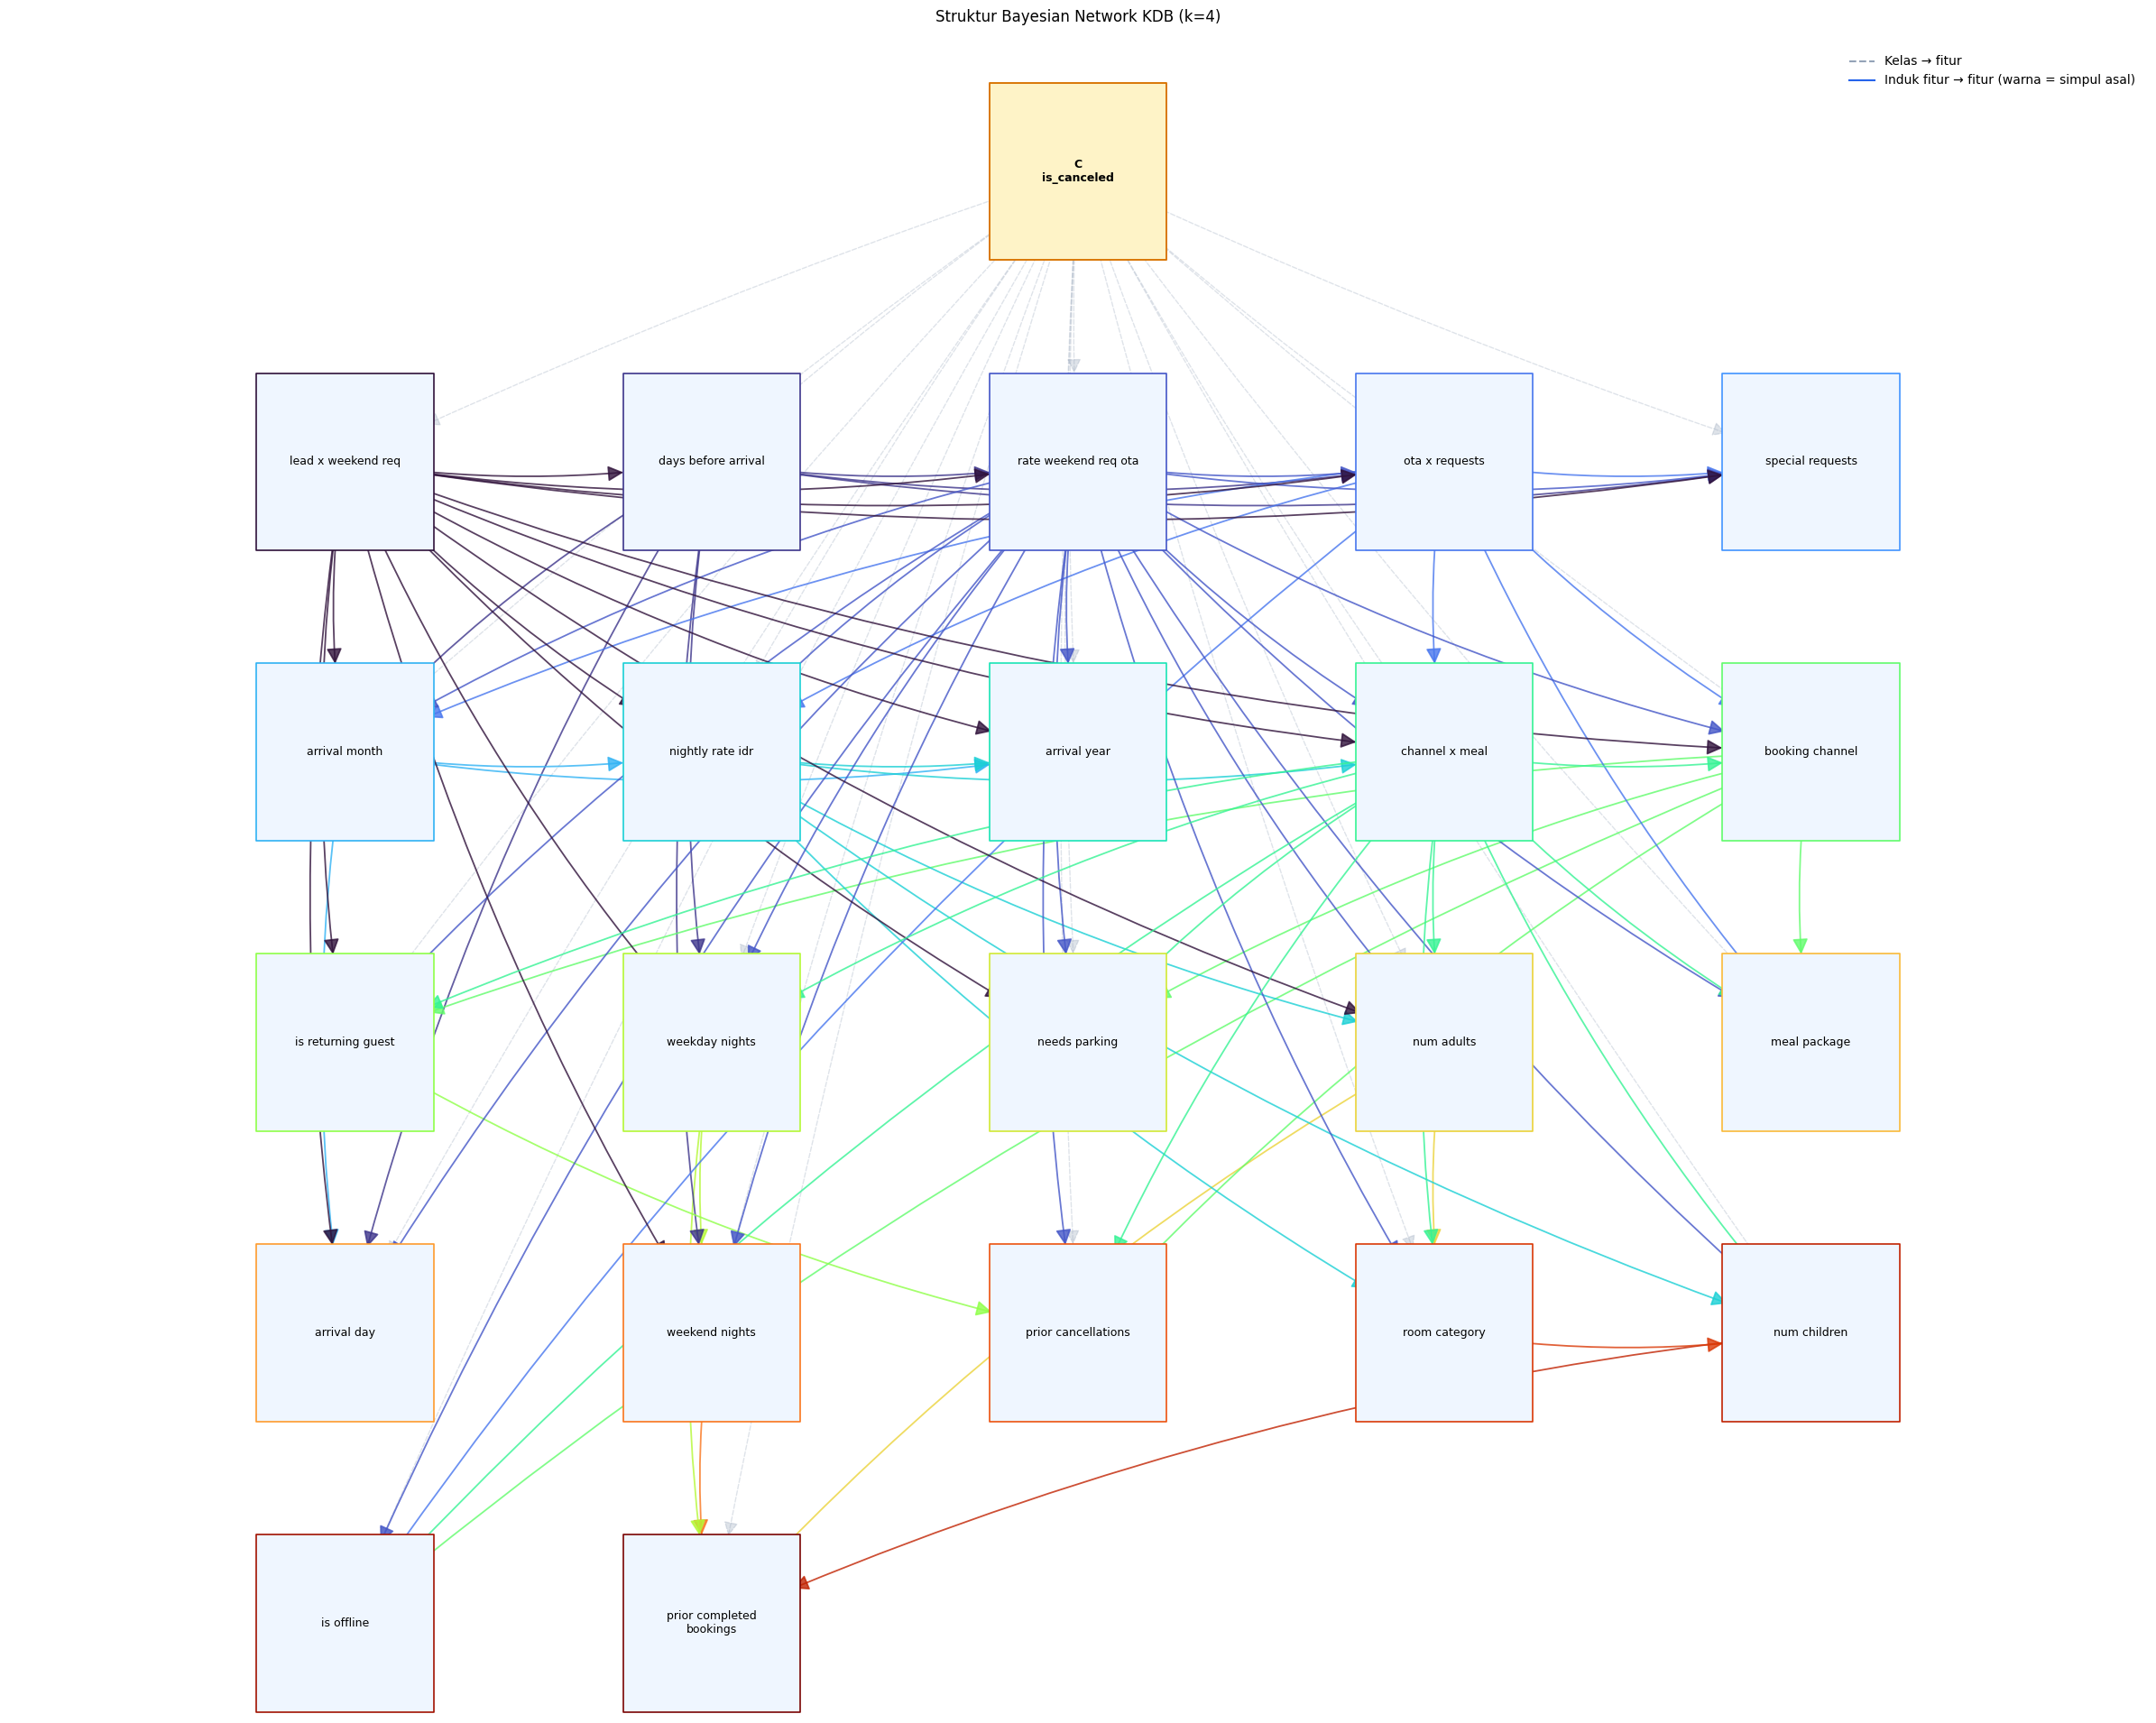

In [24]:
import shutil

network_graph_path = CFG.OUTPUT_DIR / 'naive_bayes_bayesian_network.png'
network_graph = model.plot_structure(
    network_graph_path,
    preprocessor.pre_.feature_names_,
)
report_graph_path = CFG.ROOT_DIR / 'docs' / 'laporan-akhir' / 'public' / '04-hasil-eksperimen-dan-analisis' / network_graph_path.name
report_graph_path.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(network_graph_path, report_graph_path)
print(f'Graf disimpan ke {network_graph_path} dan {report_graph_path}')
display(network_graph)
import matplotlib.pyplot as plt
plt.close(network_graph)